In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import geopandas as gpd
from shapely import wkt
from shapely.geometry import box
from shapely.geometry import Point
from shapely.ops import nearest_points
from scipy.spatial import cKDTree
from sklearn.impute import SimpleImputer

from osgeo import gdal
from scipy.interpolate import griddata
from scipy.spatial import distance
from scipy.spatial import cKDTree
from pyproj import CRS, Proj, Transformer
from shapely.geometry import box

from datetime import datetime, timedelta

import xarray as xr
import rioxarray as rxr
import os
from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

# Base grids - 1km

In [2]:
grid = pd.read_csv('grid_proj_1km.csv')[['x', 'y', 'geometry', 'lon', 'lat']]

grid['geometry'] = grid['geometry'].apply(wkt.loads)

grid_gdf = gpd.GeoDataFrame(grid, geometry='geometry', crs='ESRI:102003')

In [3]:
states = gpd.read_file('us_boundaries/States/conus_states.shp')
five_states = states.loc[states['STUSPS'].isin(['NY','PA','OH','MD','WV'])]

polygon = box(-84, 37, -74, 43.5)
region = five_states.clip(polygon)
region_proj = region.to_crs('ESRI:102003')

res = 1000

min_x, min_y, max_x, max_y = region_proj.total_bounds

xnew = np.arange(min_x, max_x, res)
ynew = np.arange(min_y, max_y, res)

x_1km, y_1km = np.meshgrid(xnew,ynew)

transformer = Transformer.from_crs("ESRI:102003", "EPSG:4326", always_xy=True)

lon, lat = transformer.transform(x_1km, y_1km)

min_lon = lon.min()
max_lon = lon.max()
min_lat = lat.min()
max_lat = lat.max()

# Batch process OMI NO2 to 1km grids

In [ ]:
omi_no2_path = 'OMI NO2/'

files = [f for f in os.listdir('OMI_vs_NO2/') if f.endswith('csv')]
files.sort()

In [ ]:
for f in files:

    date = f.split('.')[0]
    print(date)
    
    if not os.path.exists('OMI_vs_NO2/1km_grid/'+date+'.csv'):
    
        year, month, day = date[:4], date[5:7], date[8:]
        date_ = '_'+year +'m' + month + day
        omi_no2_files = [f for f in os.listdir(omi_no2_path) if date_ in f]
    
        if len(omi_no2_files) == 0:
    
            print('no OMI data')
    
        elif len(omi_no2_files) == 1:
        
            ds = rxr.open_rasterio(omi_no2_path + omi_no2_files[0])
            
            ds = ds.where(ds!=ds['HDFEOS_GRIDS_ColumnAmountNO2_Data_Fields_ColumnAmountNO2CloudScreened']._FillValue, np.nan)
            no2 = ds['HDFEOS_GRIDS_ColumnAmountNO2_Data_Fields_ColumnAmountNO2CloudScreened']
            
            no2 = no2.reduce(np.nanmean, dim='band')
            
            no2 = no2.where(no2 >= 0, np.nan)
            
            min_lon, max_lon = -84, -74
            min_lat, max_lat = 37, 43.5
            
            lon_coords = np.linspace(-179.875, 179.875, 1440)
            lat_coords = np.linspace(-89.875, 89.875, 720)
            
            no2 = no2.assign_coords({'x': lon_coords, 'y': lat_coords})
    
            lats = xr.DataArray(grid_gdf.lat, dims='z') #'z' is an arbitrary name placeholder
            lons = xr.DataArray(grid_gdf.lon, dims='z')
            grid_gdf['no2'] = no2.sel(x=lons, y=lats, method='nearest')
    
            grid_gdf[['no2']].to_csv('OMI_vs_NO2/1km_grid/'+date+'.csv', index=False)

# Base grids - 5km

In [27]:
grid = pd.read_csv('grid_proj_5km.csv')[['x', 'y', 'geometry', 'lon', 'lat']]

grid['geometry'] = grid['geometry'].apply(wkt.loads)

grid_gdf = gpd.GeoDataFrame(grid, geometry='geometry', crs='ESRI:102003')

In [28]:
states = gpd.read_file('us_boundaries/States/conus_states.shp')
five_states = states.loc[states['STUSPS'].isin(['NY','PA','OH','MD','WV'])]

polygon = box(-84, 37, -74, 43.5)
region = five_states.clip(polygon)
region_proj = region.to_crs('ESRI:102003')

res = 5000

min_x, min_y, max_x, max_y = region_proj.total_bounds

xnew = np.arange(min_x, max_x, res)
ynew = np.arange(min_y, max_y, res)

x_5km, y_5km = np.meshgrid(xnew,ynew)

transformer = Transformer.from_crs("ESRI:102003", "EPSG:4326", always_xy=True)

lon, lat = transformer.transform(x_5km, y_5km)

min_lon = lon.min()
max_lon = lon.max()
min_lat = lat.min()
max_lat = lat.max()

# Batch process OMI NO2 to 5km grids

In [ ]:
omi_no2_path = 'OMI NO2/'

files = [f for f in os.listdir('OMI_vs_NO2/') if f.endswith('csv')]
files.sort()

In [ ]:
for f in files:

    date = f.split('.')[0]
    print(date)
    
    if not os.path.exists('OMI_vs_NO2/5km_grid/'+date+'.csv'):
    
        year, month, day = date[:4], date[5:7], date[8:]
        date_ = '_'+year +'m' + month + day
        omi_no2_files = [f for f in os.listdir(omi_no2_path) if date_ in f]
    
        if len(omi_no2_files) == 0:
    
            print('no OMI data')
    
        elif len(omi_no2_files) == 1:
        
            ds = rxr.open_rasterio(omi_no2_path + omi_no2_files[0])
            
            ds = ds.where(ds!=ds['HDFEOS_GRIDS_ColumnAmountNO2_Data_Fields_ColumnAmountNO2CloudScreened']._FillValue, np.nan)
            no2 = ds['HDFEOS_GRIDS_ColumnAmountNO2_Data_Fields_ColumnAmountNO2CloudScreened']
            
            no2 = no2.reduce(np.nanmean, dim='band')
            
            no2 = no2.where(no2 >= 0, np.nan)
            
            min_lon, max_lon = -84, -74
            min_lat, max_lat = 37, 43.5
            
            lon_coords = np.linspace(-179.875, 179.875, 1440)
            lat_coords = np.linspace(-89.875, 89.875, 720)
            no2 = no2.assign_coords({'x': lon_coords, 'y': lat_coords})
    
            lats = xr.DataArray(grid_gdf.lat, dims='z') #'z' is an arbitrary name placeholder
            lons = xr.DataArray(grid_gdf.lon, dims='z')
            grid_gdf['no2'] = no2.sel(x=lons, y=lats, method='nearest')
    
            grid_gdf[['no2']].to_csv('OMI_vs_NO2/5km_grid/'+date+'.csv', index=False)

In [33]:
ds = xr.Dataset(
    {
        'no2': (('y', 'x'), grid_gdf['no2'].values.reshape(x_5km.shape))
    },
    coords={
        'lat': (('y', 'x'), lat),
        'lon': (('y', 'x'), lon),
        'Projected Y': (('y', 'x'), y_5km),
        'Projected X': (('y', 'x'), x_5km),
    }
)

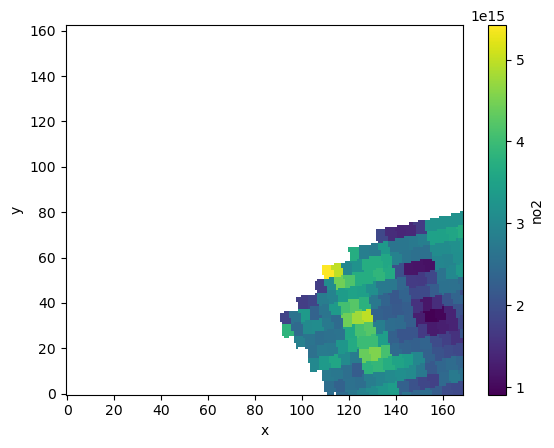

In [34]:
ds.no2.plot()